### Model Performance Measurement

**Choosing the right metrics**
Different evaluation metrics answer different questions. There is no one-size-fits-all approach or single metric that describes model performance. Evaluation metrics reveal different aspects of classification and regression performance.

* **Confusion matrix:** shows which classes are missed, helping to distinguish false positives from false negatives. 
* **Precision, recall, and F1 scores** reveal class differences that overall accuracy can hide. Averaging methods influence reported scores: macro averages weight classes equally, while weighted averages account for class frequency.
* **ROC AUC** measures how well scores separate classes across thresholds, while log loss evaluates probabilities and penalises confident mistakes.
* For regression,**MAE, MSE, and R²** assess numerical predictions: mean absolute error, mean squared error, and improvement over a mean-prediction baseline.

**Metric selection should reflect the task and the cost of errors.** For instance, accuracy treats every incorrect classification equally but in practice, a false positive and a false negative can have very different real-world impact (e.g. spam / non spam, vs cancer vs no-cancer).

**Evaluation Reliability:** 
Evaluation design is critical. Scores measured on training data do not indicate performance on unseen examples. Near-perfect scores calculated on training data do not establish generalisation. Test data is critical for assessing how well a model performs on examples it did not learn from.

Ideally,
* Training data: used to learn the model’s parameters.
* Validation set: used to tune settings and compare models.
* Test set: used for final evaluation after model selection and tuning.

**Model Configuration and Improvement**
I applied these evaluation principles to compare model configurations. By changing noise levels, regularisation and kernel settings, I observed their effects on AUC. This connected the interpretation of performance metrics with practical decisions about model selection and hyperparameter tuning.


#### Confusion Matrix
It helps compare the actual labels with model's predicted labels.

In [7]:
from sklearn.metrics import confusion_matrix

In [8]:
tn, fp, fn, tp = confusion_matrix([0, 1, 0, 1], [1, 1, 1, 0]).ravel()
(tn, fp, fn, tp)

(np.int64(0), np.int64(2), np.int64(1), np.int64(1))

actual    = [0, 1, 0, 1]
predicted = [1, 1, 1, 0]

### Example: Create artificial data, train a support vector classifier (SVC), and display its confusion matrix.

* The data is split by default: 75% is used for training and 25% for testing. 
* The test set allows me to assess predictions on examples excluded from training.

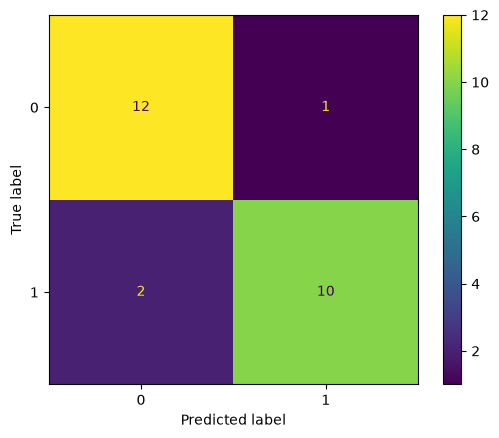

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
X, y = make_classification(random_state=0)                      # Create the data
X_train, X_test, y_train, y_test = train_test_split(X, y,random_state=0) # Apply the split train / test
clf = SVC(random_state=0)
clf.fit(X_train, y_train)                                       # Create and train the classifier
SVC(random_state=0)
predictions = clf.predict(X_test)                                # Predict the test labels
cm = confusion_matrix(y_test, predictions, labels=clf.classes_)  # Compare predictions with actual labels
disp = ConfusionMatrixDisplay(confusion_matrix=cm,               # display confusion matrix
                               display_labels=clf.classes_)
disp.plot()

plt.show()


* true negatives - 12 
* true positives - 10
* False positives - 1
* False negatives - 2

Results:
* 22 correct predictions out of 25 (Accuracy: 22/25 = 88%)
* of 13 actual negatives, 12 were correctly classified and 1 was incorrectly predicted positive.
* of 12 actual positives, 10 were correctly classified and 2 were missed.

#### F1, Accuracy, Recall, AUC and Precision scores

* Accuracy: proportion of predictions that match the labels.
* Precision: when the model predicts a class, how often it is correct.
* Recall: how many examples belonging to a class it identifies.
* F1: combines precision and recall.

In [ ]:
from sklearn.metrics import f1_score

# Example 1: Multiclass classification: one class per example
y_true = [0, 1, 2, 0, 1, 2]
y_pred = [0, 2, 1, 0, 0, 1]

print(f"Macro f1 score: {f1_score(y_true, y_pred, average='macro')}")
print(f"Micro F1: {f1_score(y_true, y_pred, average='micro')}")
print(f"Weighted Average F1: {f1_score(y_true, y_pred, average='weighted')}")
print(f"F1 No Average: {f1_score(y_true, y_pred, average=None)}")

# Example 2: No positive examples or predictions
y_true = [0, 0, 0, 0, 0, 0]                    # no labels
y_pred = [0, 0, 0, 0, 0, 0]                    # predicted correctly
f1_score(y_true, y_pred, zero_division=1)

# Example 3: Multilabel classification, 3 labels per example                     
y_true = [[0, 0, 0], [1, 1, 1], [0, 1, 1]]      # 3 labels
y_pred = [[0, 0, 0], [1, 1, 1], [1, 1, 0]]      
print(f"F1 No Average: {f1_score(y_true, y_pred, average=None)}")


Macro f1 score: 0.26666666666666666
Micro F1: 0.3333333333333333
Weighted Average F1: 0.26666666666666666
F1 No Average: [0.8 0.  0. ]
F1 No Average: [0.66666667 1.         0.66666667]


The prediction perfomance can be summarised in different ways. 
* F1 No Average: [0.8 0.  0. ] - Class 0 has F1 of 0.8. Classes 1 and 2 have F1 of 0.
* Macro f1 score: 0.267 - The average of the 3 class scores: (0.8 + 0 + 0) ÷ 3. Every class matters equally.
* Micro F1: 0.333 - Combines prediction counts across classes. It equals accuracy: 2 correct out of 6.
* Weighted F1: 0.267 - Averages class scores according to how many actual examples each class has. Because all 3 classes have two examples, it matches macro F1.
* F1 No Average: [0.667 1. 0.667] - comes from multilabelled data, 1 - one false positive, 2 - no error, 3 - one false negative

**Takeway:** An overall average can hide struggling classes struggl and per-class scores reveal the differences. The confision matrix provide the context of the mistakes.

In [12]:
from sklearn.metrics import accuracy_score
y_pred = [0, 2, 1, 3]
y_true = [0, 1, 2, 3]
accuracy_score(y_true, y_pred)

0.5

**Accuracy:** proportion of predictions that match the labels. In this case 50% of observations (2 of 4) were matched correctly. The order matters here and each prediction was compared with the actual label at the same position.

In [13]:
from sklearn.metrics import precision_score
y_true = [0, 1, 2, 0, 1, 2]
y_pred = [0, 2, 1, 0, 0, 1]
precision_score(y_true, y_pred, average='macro')

0.2222222222222222

**Macro precision** calculates precision for each class out of 3 classess (0, 1, 2), and then averages the scores equally. How often is the prediction correct?
22.2% is the avergae prediction across classes. 

In [17]:
from sklearn.metrics import recall_score
y_true = [0, 1, 2, 0, 1, 2]
y_pred = [0, 2, 1, 0, 0, 1]
recall_score(y_true, y_pred, average='macro')

0.3333333333333333

**Macro recall** calculates recall for each class, then averages the scores equally. 
How many examples belonging to a class are identified?

Macro recall = (1 + 0 + 0) / 3 = 33.33% 

The first class 0 was perfectly predicted, as opposed to 2 others classess that were missed. 

In [14]:
from sklearn.metrics import classification_report
y_true = [0, 1, 2, 2, 2]
y_pred = [0, 0, 2, 2, 1]
target_names = ['class 0', 'class 1', 'class 2']
print(classification_report(y_true, y_pred, target_names=target_names))

              precision    recall  f1-score   support

     class 0       0.50      1.00      0.67         1
     class 1       0.00      0.00      0.00         1
     class 2       1.00      0.67      0.80         3

    accuracy                           0.60         5
   macro avg       0.50      0.56      0.49         5
weighted avg       0.70      0.60      0.61         5



**Class 0**
- Precision 0.50: 2 predictions of class 0, but 1 one was correct.
- Recall 1.00: 1 actual class-0 example was found.

**Class 1**
- Precision and recall 0: Actual example was missed, predicted example was incorrect

**Class 2**
- Precision 1.00: 2 predictions of class 2 were correct.
- Recall 0.67: 2 of its 3 actual examples were found.


- Support: how many actual examples belong to each class.
- Accuracy = 0.60%: 3 correct predictions out of 5.
- Macro average: gives each class equal weight.
- Weighted average: gives class 2 more weight because it has 3 of the 5 examples.

Class 0 finds all its examples but makes an extra false prediction; class 2 makes no false predictions but misses one example.

### Logistic regression classifier - ROC AUC

*  ROC AUC measure how well its scores distinguish the two classes


In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
X, y = load_breast_cancer(return_X_y=True)
clf = LogisticRegression(solver="liblinear", random_state=0).fit(X, y)
roc_auc_score(y, clf.predict_proba(X)[:, 1])


0.994714867078907

ROC AUC is 0.995 indicates a very strong separation of the two classes on the training data. For a randomly selected benign and malignant example, the model gives the benign example a higher benign-class score about 99.47% of the time.

### Iris Classification Example

In [18]:
#multiclass case
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

clf = LogisticRegression(solver="lbfgs",max_iter=1000).fit(X, y)

roc_auc_score(y,clf.predict_proba(X),multi_class="ovr")

0.9984000000000001

ROC AUC is 0.9984, indicating almost perfect separation on the training data. It measures how well the probability scores rank examples by class.

NOTE: 
multi_class="ovr":
1. Evaluates each Iris class against the other two.
2. Calculates an AUC for each comparison.
3. Averages the three AUC scores equally.

## Tested changes: 
1. Noise multiplier (0, 50, 200, 500)
2. Regularization strength (0.01, 1, 100), noise held fixed at 200
3. Kernel (“linear”, “rbf”, “poly”), noise and C held fixed

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import cycle

from sklearn import svm, datasets
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score

# Import some data to play with
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Binarize the output
y = label_binarize(y, classes=[0, 1, 2])
n_classes = y.shape[1]

# Add noisy features to make the problem harder
random_state = np.random.RandomState(0)
n_samples, n_features = X.shape
X = np.c_[X, random_state.randn(n_samples, 500 * n_features)]

# shuffle and split training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

# Learn to predict each class against the other
classifier = OneVsRestClassifier(
    svm.SVC(kernel="linear", C= 1, probability=True, random_state=random_state)
)
y_score = classifier.fit(X_train, y_train).decision_function(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# --- print results ---
for i in range(n_classes):
    print(f"Class {i} AUC: {roc_auc[i]:.4f}")
print(f"Micro-average AUC: {roc_auc['micro']:.4f}")

Class 0 AUC: 0.8404
Class 1 AUC: 0.6074
Class 2 AUC: 0.7296
Micro-average AUC: 0.6675


## Test RESULTS: 
1. Noise multiplier (0, 50, 200, 500)
* 0 - AUC: 0.9156
* 50 - AUC: 0.8252
* 200 - AUC: 0.7277
* 500 -  AUC: 0.6675

2. C - Regularization strength (0.01, 1, 100), noise held fixed at 200
* 0.00001 - AUC: 0.6614
* 0.01 - AUC: 0.7277
* 1 - AUC: AUC: 0.7277
* 100 - AUC:0.7277

3. Kernel (“linear”, “rbf”, “poly”), noise and C held fixed
* “linear” - AUC: 0.7277
* “rbf” - AUC: 0.5939
* “poly” - AUC: 0.5301

**Takeways:**
- The more noise the model gets, the harder it is to distinguish between the classes. Adding noise features does not remove the original signal. It makes useful patterns harder to identify.
- A smaller C means stronger regularisation and greater tolerance for training errors. An extremely small value can cause underfitting.
- Kernel - the simple linear models won, not the more complex ones that got distracted by the noise.

Adding more random noise features reduced the model’s ability to distinguish between classes, as measured by ROC AUC. Very small C values also reduced performance, suggesting that strong regularisation restricted the model too much. The linear kernel performed better than the nonlinear alternatives. These results showed that greater model flexibility does not automatically improve performance, particularly when many features are irrelevant. 

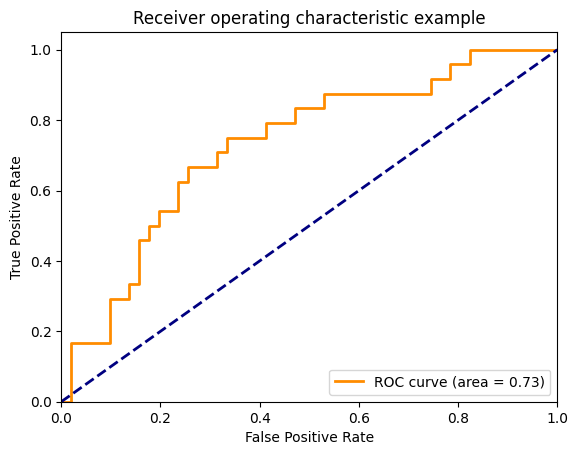

In [24]:
# Visualise
plt.figure()
lw = 2
plt.plot(
    fpr[2],
    tpr[2],
    color="darkorange",
    lw=lw,
    label="ROC curve (area = %0.2f)" % roc_auc[2],
)
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic example")
plt.legend(loc="lower right")
plt.show()


* Orange line shows the ROC curve for class-2 against the other two classes. 
* AUC of 0.79 means the model ranks a randomly selected class-2 example above a randomly selected non-class-2 example about 79% of the time but this is lower than 0.9984 in the example above because of added noise, test data and a score for one class, rather than an average across all three classes.

In [22]:
## Log loss calculation
from sklearn.metrics import log_loss
log_loss(["spam", "ham", "ham", "spam"], [[.1, .9], [.9, .1], [.8, .2], [.35, .65]])

0.21616187468057912

**Log loss** evaluates the probabilities assigned to the correct class. It penalises confident mistakes heavily. Lower is better, with 0 representing perfect predictions. Each pair means: [probability of ham, probability of spam] (alphabetically ordered).

### Regression metrics - predicting numerical values

#### MSE (mean square error)
* Mean squared error (MSE) - the average of the squared prediction errors.
* Lower is better where 0 means every prediction is exact. 
* Squaring prevents positive and negative errors from cancelling and gives larger errors more weight. 
* MSE is measured in squared target units, not percentages.

In [27]:
from sklearn.metrics import mean_squared_error
y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]
mean_squared_error(y_true, y_pred)

0.375

#### MAE
* Mean absolute error (MAE) averages the size of the errors,. It ignores whether predictions are too high or too low.
* predictions are 0.5 target units away from the actual values on average

MAE does not square the errors (unlike MSE), hence it is less sensitive to large mistakes and remains in the same units as the target. 
Lower is better, with 0 being perfect predictions.

In [28]:
from sklearn.metrics import mean_absolute_error
y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]
mean_absolute_error(y_true, y_pred)

0.5

#### R squared

R squared compares the model’s squared errors with a baseline that always predicts the mean of the actual values.

* 1: perfect predictions
* 0: the same squared error as predicting the mean
* Below 0: worse than that baseline.

0.948 - predictions reduce squared error by approximately 94.9% compared with the mean baseline.

In [29]:
from sklearn.metrics import r2_score

r2_score(y_true, y_pred)

0.9486081370449679